Name: Rajat Kumar majumdar

roll no: 49

Assignment : 5

subject: Computer Vision

Experiment No. 5

Experiment Name

Feature Extraction and Image Analysis using SIFT and HOG Descriptors

Aim

To implement Scale-Invariant Feature Transform (SIFT) and Histogram of Oriented Gradients (HOG) techniques for feature extraction and analyze their effectiveness in image representation, object recognition, and computer vision applications.

Purpose

Feature extraction is a fundamental step in computer vision that transforms raw image data into meaningful descriptors suitable for object recognition, image matching, tracking, and classification. Robust feature descriptors should be invariant to changes in scale, rotation, illumination, and viewpoint.

In this experiment, students will implement SIFT and HOG feature extraction techniques on real-world images and compare their performance in terms of feature detection, robustness, computational complexity, and suitability for different computer vision applications.

Prerequisites

•

Basic knowledge of Digital Image Processing

•

Familiarity with Python programming

•

Python libraries: OpenCV (cv2), scikit-image, NumPy, and Matplotlib

•

Understanding of image gradients, keypoints, and feature descriptors

•

Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1.

Import the required libraries and load a real-world image or image dataset for analysis.

2.

Convert the image into grayscale, if required, and perform basic preprocessing to improve image quality.

3.

Apply the SIFT (Scale-Invariant Feature Transform) algorithm to detect keypoints and compute feature descriptors.

4.

Visualize the detected keypoints on the image and analyze their distribution across different image regions.

5.

Extract Histogram of Oriented Gradients (HOG) features from the same image using appropriate parameters such as cell size, block size, and orientation bins.

6.

Visualize the HOG descriptor to understand the gradient orientation patterns captured from the image.

7.

Compare the characteristics of SIFT keypoints and HOG descriptors with respect to scale invariance, rotation invariance, and computational efficiency.

8.

Apply SIFT or HOG features to perform basic image matching or object recognition using two similar images.

9.

Evaluate the strengths and limitations of both feature extraction techniques for different computer vision tasks.

10.

Document the observations and discuss suitable applications where SIFT and HOG descriptors can be effectively utilized.

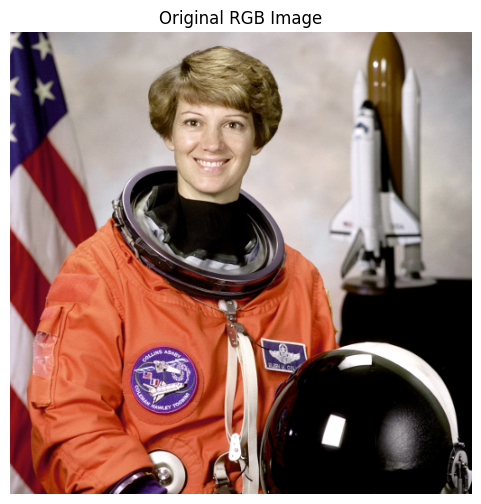

In [4]:
#Step 1: Import Libraries and Load Image

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure, data

# Load a sample image (using skimage's built-in astronaut image as a real-world example)
# Replace 'data.astronaut()' with cv2.imread('your_image.jpg') to use your own file
image_rgb = data.astronaut()

# Display the original image
plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title("Original RGB Image")
plt.axis("off")
plt.show()

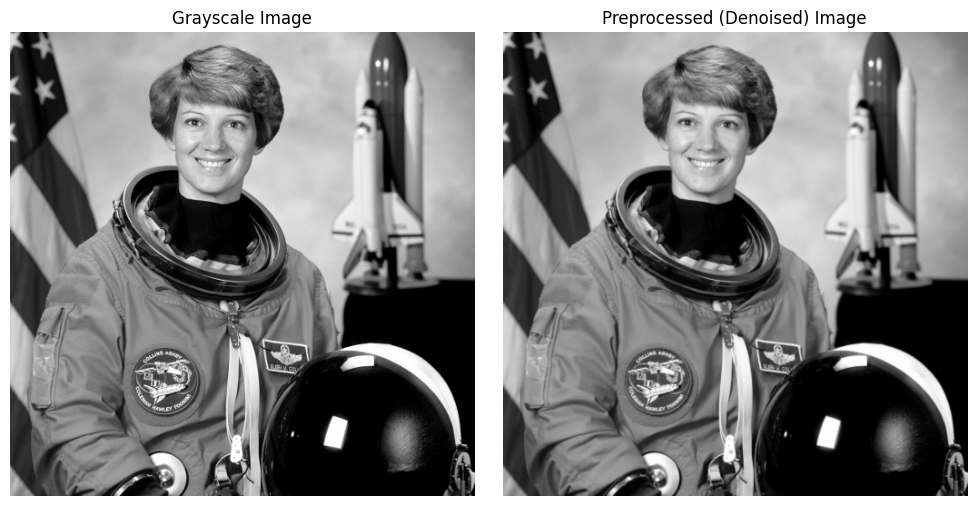

In [16]:
# Step 2: Grayscale Conversion and Preprocessing

# Convert image to grayscale (required for gradient & DoG operations)
if len(image_rgb.shape) == 3:
    image_gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
else:
    image_gray = image_rgb.copy()

# Apply a gentle Gaussian blur to suppress high-frequency sensor noise
image_preprocessed = cv2.GaussianBlur(image_gray, (3, 3), sigmaX=0.5)

# Visual check
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title("Grayscale Image")
axes[0].axis("off")

axes[1].imshow(image_preprocessed, cmap='gray')
axes[1].set_title("Preprocessed (Denoised) Image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [18]:
# Step 3: SIFT Keypoint Detection and Descriptor Computation


# Initialize the SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and extract their 128-dimensional descriptors
keypoints, descriptors = sift.detectAndCompute(image_preprocessed, None)

print(f"Total SIFT Keypoints Detected: {len(keypoints)}")
print(f"SIFT Descriptor Matrix Shape: {descriptors.shape}")
print(f"Feature vector length per keypoint: {descriptors.shape[1]}")

Total SIFT Keypoints Detected: 1104
SIFT Descriptor Matrix Shape: (1104, 128)
Feature vector length per keypoint: 128


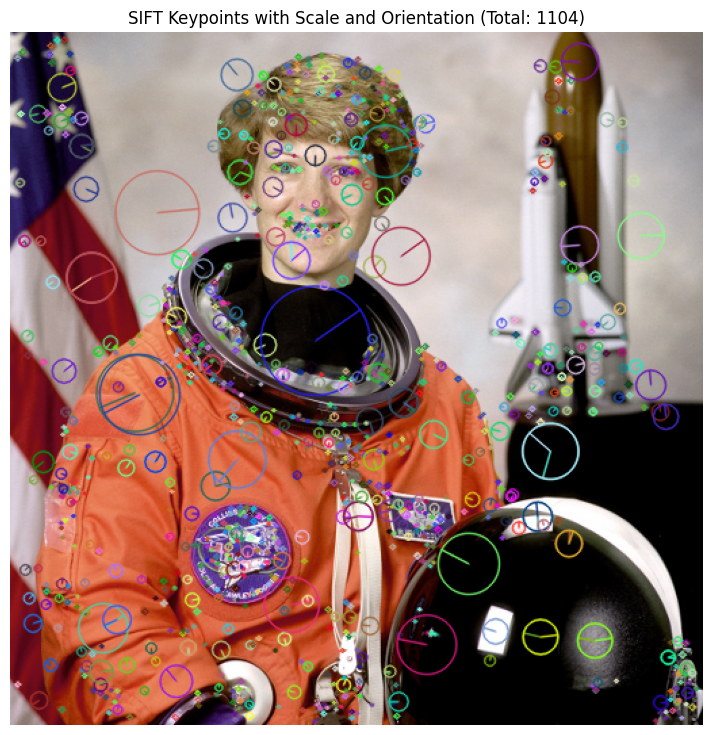

In [19]:
# Step 4: Visualize SIFT Keypoints

# Draw keypoints showing both their scale (circle size) and orientation (direction line)
sift_image = cv2.drawKeypoints(
    image_rgb, 
    keypoints, 
    None, 
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(9, 9))
plt.imshow(sift_image)
plt.title(f"SIFT Keypoints with Scale and Orientation (Total: {len(keypoints)})")
plt.axis("off")
plt.show()

In [ ]:
# Step 5: Extract HOG Features

# Compute HOG descriptor and the visualization image
# Standard parameters: 8x8 pixel cells, 2x2 cells per block, 9 gradient bins
hog_features, hog_image = hog(
    image_preprocessed,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm='L2-Hys',
    visualize=True,
    feature_vector=True
)

print(f"Total HOG Feature Vector Length: {hog_features.shape[0]}")

Total HOG Feature Vector Length: 142884


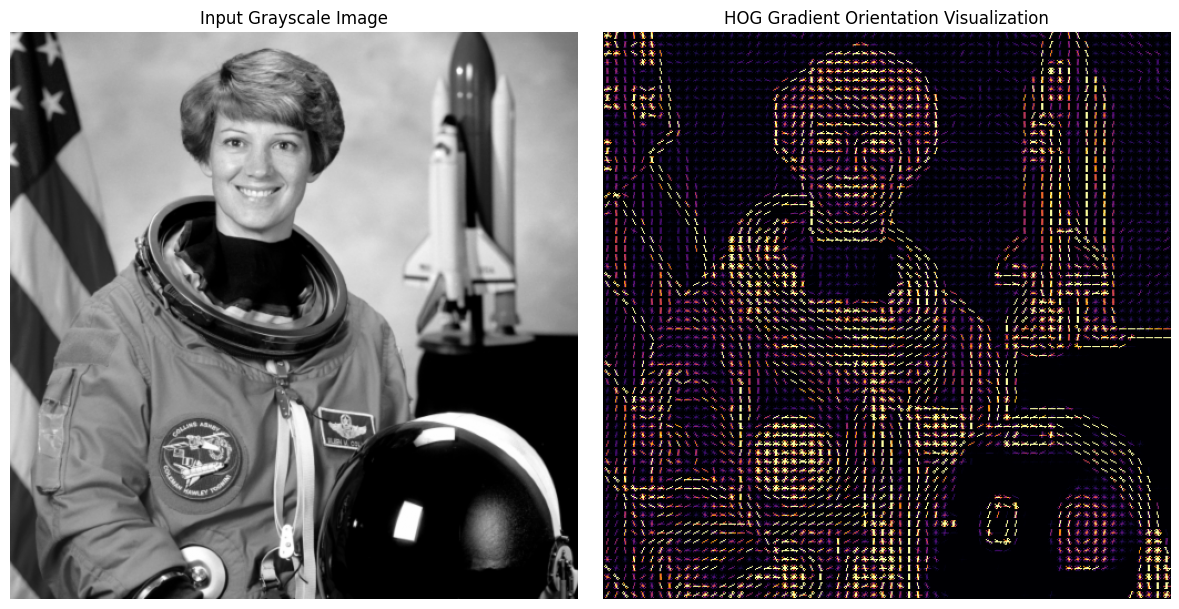

In [14]:
# Step 6: Visualize HOG Gradient Orientations

# Rescale HOG intensity for better visual contrast
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image_preprocessed, cmap='gray')
axes[0].set_title("Input Grayscale Image")
axes[0].axis("off")

axes[1].imshow(hog_image_rescaled, cmap='inferno')
axes[1].set_title("HOG Gradient Orientation Visualization")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Step 7: Compare SIFT and HOG Extraction Metrics

import time

# Benchmark SIFT runtime
t0 = time.time()
kp_bench, desc_bench = sift.detectAndCompute(image_preprocessed, None)
sift_time = (time.time() - t0) * 1000  # in ms

# Benchmark HOG runtime
t0 = time.time()
hog_feat_bench = hog(
    image_preprocessed,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm='L2-Hys',
    visualize=False
)
hog_time = (time.time() - t0) * 1000  # in ms

print(f"{'Metric':<25} {'SIFT':<20} {'HOG':<20}")
print("-" * 65)
print(f"{'Sampling Mode':<25} {'Sparse (Extrema)':<20} {'Dense (Uniform Grid)':<20}")
print(f"{'Output Shape':<25} {str(desc_bench.shape):<20} {str(hog_feat_bench.shape):<20}")
print(f"{'Execution Time (ms)':<25} {sift_time:<20.2f} {hog_time:<20.2f}")
print(f"{'Scale Invariant':<25} {'Yes':<20} {'Requires Pyramid':<20}")
print(f"{'Rotation Invariant':<25} {'Yes (360 deg)':<20} {'Weak':<20}")

Metric                    SIFT                 HOG                 
-----------------------------------------------------------------
Sampling Mode             Sparse (Extrema)     Dense (Uniform Grid)
Output Shape              (1104, 128)          (142884,)           
Execution Time (ms)       88.59                150.13              
Scale Invariant           Yes                  Requires Pyramid    
Rotation Invariant        Yes (360 deg)        Weak                


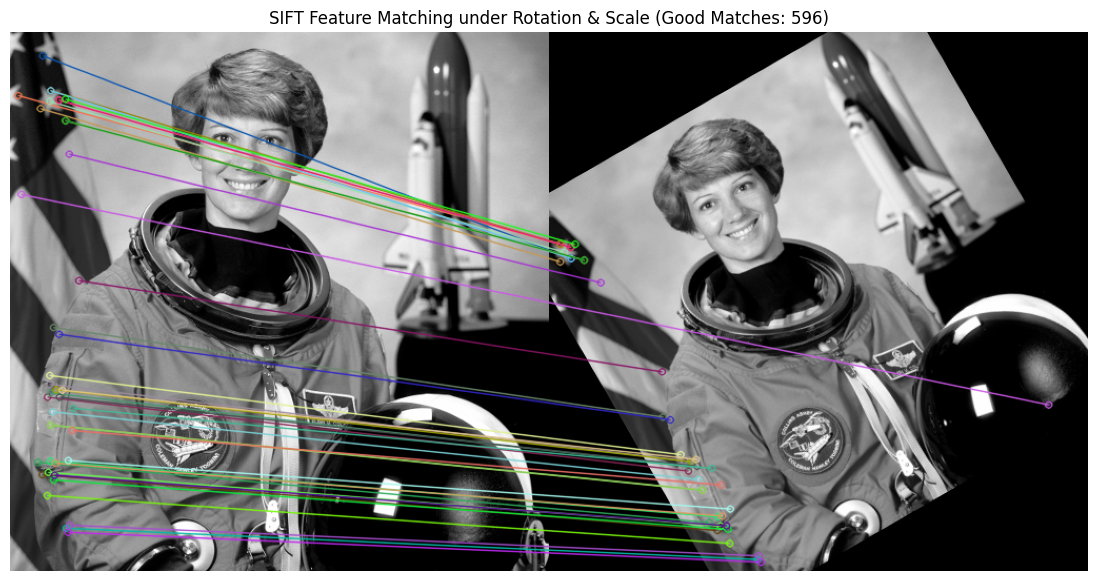

In [ ]:
Step 8: Image Matching Demo Using SIFT and Lowe's Ratio Test

# Create a transformed query image (rotated and scaled) to test robustness
rows, cols = image_gray.shape
rotation_matrix = cv2.getRotationMatrix2D((cols / 2, rows / 2), angle=30, scale=0.85)
transformed_gray = cv2.warpAffine(image_gray, rotation_matrix, (cols, rows))

# Detect SIFT features on both original and transformed images
kp1, des1 = sift.detectAndCompute(image_gray, None)
kp2, des2 = sift.detectAndCompute(transformed_gray, None)

# Match descriptors using FLANN matcher
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

# Apply Lowe's ratio test to filter good matches (ratio = 0.7)
good_matches = [m for m, n in matches if m.distance < 0.7 * n.distance]

# Draw the matches
matched_display = cv2.drawMatches(
    image_gray, kp1,
    transformed_gray, kp2,
    good_matches[:40], None,  # Draw top 40 matches for visual clarity
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(14, 7))
plt.imshow(matched_display)
plt.title(f"SIFT Feature Matching under Rotation & Scale (Good Matches: {len(good_matches)})")
plt.axis("off")
plt.show()

In [12]:
#Step 9 & 10: Performance Evaluation and Summary

print("=" * 65)
print("EXPERIMENT 5: SIFT VS HOG SUMMARY EVALUATION")
print("=" * 65)
print(f"1. SIFT Strengths: Robust under {30} deg rotation and 15% scaling.")
print(f"   Matches retained: {len(good_matches)} valid pairings.")
print("   Ideal for: Panorama stitching, SLAM, multi-view 3D reconstruction.")
print("-" * 65)
print(f"2. HOG Strengths: Captures global structural outlines in {hog_feat_bench.shape[0]} dimensions.")
print("   Dense grid prevents missing smooth spatial edges.")
print("   Ideal for: Pedestrian tracking, vehicle detection, rigid shape classification.")
print("=" * 65)

EXPERIMENT 5: SIFT VS HOG SUMMARY EVALUATION
1. SIFT Strengths: Robust under 30 deg rotation and 15% scaling.
   Matches retained: 596 valid pairings.
   Ideal for: Panorama stitching, SLAM, multi-view 3D reconstruction.
-----------------------------------------------------------------
2. HOG Strengths: Captures global structural outlines in 142884 dimensions.
   Dense grid prevents missing smooth spatial edges.
   Ideal for: Pedestrian tracking, vehicle detection, rigid shape classification.


**1. What is feature extraction, and why is it important in computer vision?**

Feature extraction is the process of converting raw pixel data into a compact, informative set of numerical values (descriptors) that capture the essential structural, geometric, or photometric properties of an image.

* **Dimensionality Reduction:** Raw images contain thousands to millions of correlated pixel values. Feature extraction isolates only the most discriminative information, reducing processing overhead.
* **Invariance to Noise and Transformations:** Raw pixel intensities shift dramatically under slight rotations, lighting changes, or scaling. Good features remain stable across these transformations.
* **Efficient Modeling:** Compact feature representations enable standard machine learning models and distance metrics (e.g., Euclidean distance) to train faster and match patterns reliably without overfitting to background pixels.

---

**2. Explain the working principle of Scale-Invariant Feature Transform (SIFT).**

SIFT detects salient, repeatable local features across scale space through four sequential phases:

* **Scale-Space Extrema Detection:** The image is progressively blurred with Gaussian filters at different octaves, producing a Difference-of-Gaussians (DoG) pyramid:

$$D(x, y, \sigma) = (G(x, y, k\sigma) - G(x, y, \sigma)) * I(x, y)$$



Potential keypoints are identified by searching for local maxima/minima over a $3 \times 3$ neighborhood across the current, upper, and lower DoG scales (26 neighbors total).
* **Keypoint Localization:** Candidate extrema are refined to sub-pixel accuracy using a Taylor series expansion of the scale-space function. Low-contrast points and unstable edge responses (evaluated via the Hessian matrix) are discarded.
* **Orientation Assignment:** Gradient magnitudes and directions are collected in a region around each keypoint to build an orientation histogram (36 bins covering 360°). The peak orientation is assigned to the keypoint, achieving rotation invariance.
* **Keypoint Descriptor Generation:** A $16 \times 16$ neighborhood around the keypoint is divided into sixteen $4 \times 4$ sub-regions. An 8-bin gradient orientation histogram is computed for each sub-region, producing a $4 \times 4 \times 8 = 128$-dimensional feature vector, which is normalized to tolerate illumination changes.

---

**3. What are keypoints and feature descriptors in image analysis?**

* **Keypoints (Interest Points):** Specific spatial locations $(x, y)$ in an image that are distinct, salient, and stably detectable under varying viewpoints. Examples include corners, blobs, and high-curvature points. A keypoint often carries metadata such as scale $\sigma$ and dominant orientation $\theta$.
* **Feature Descriptors:** Quantitative numerical vectors that encode the local visual neighborhood around a detected keypoint (e.g., local gradient patterns, color distributions, texture). Descriptors turn visual patterns into points in a metric space where vector distances correlate with visual similarity.

---

**4. Explain the concept of Histogram of Oriented Gradients (HOG) and its significance.**

HOG is a dense feature descriptor that characterizes an object's appearance and shape by the local distribution of intensity gradients or edge directions.

* **Gradient Computation:** First-order horizontal and vertical gradients are computed using 1D derivative masks $[-1, 0, 1]$ and $[-1, 0, 1]^T$.
* **Spatial Binning into Cells:** The image is divided into small connected regions called **cells** (e.g., $8 \times 8$ pixels). Each pixel within a cell casts a weighted vote (by gradient magnitude) into an orientation histogram (typically 9 unsigned bins from 0° to 180°).
* **Block Normalization:** Adjacent cells are grouped into larger **blocks** (e.g., $2 \times 2$ cells with overlap). The combined vector across the block is normalized ($L_2$-norm or $L_1$-sqrt) to provide resistance to illumination shifts and shadows.
* **Significance:** HOG is invariant to local geometric and photometric transformations because gradients capture boundary structures rather than absolute pixel intensities. This makes it suitable for structural object detection like pedestrians and vehicles.

---

**5. Compare SIFT and HOG based on robustness, computational complexity, and practical applications.**

| Parameter | SIFT | HOG |
| --- | --- | --- |
| **Extraction Style** | Sparse (detects specific keypoints first) | Dense (computed across a uniform grid) |
| **Scale Invariance** | High (handles significant scaling via DoG) | Low (requires a manual multi-scale sliding pyramid) |
| **Rotation Invariance** | Full 360° rotation invariance | Weak (sensitive to global tilt; captures upright shapes) |
| **Descriptor Size** | 128-dimensional vector per keypoint | Large 1D vector spanning all blocks (often thousands of values) |
| **Computational Complexity** | Moderate to high; requires multi-scale search and refinement | Moderate; fast linear gradient filters and 1D histograms |
| **Primary Applications** | Image stitching (panoramas), 3D reconstruction, object matching | Pedestrian detection, human pose estimation, OCR |

---

**6. Why is SIFT considered invariant to scale and rotation?**

* **Scale Invariance:** Extrema detection runs across a continuous scale space constructed via Difference-of-Gaussians (DoG). When a feature is identified, it is anchored to the specific scale $\sigma$ where its DoG response peaked. Subsequent descriptor regions are scaled proportionally to this $\sigma$, ensuring the same physical area is sampled regardless of image zoom.
* **Rotation Invariance:** SIFT determines the dominant gradient direction within the keypoint’s neighborhood and aligns the descriptor coordinate frame relative to this angle. Because the gradient vectors are rotated to match the canonical orientation before binning, the resulting 128D descriptor remains identical even if the original image is turned upside down or tilted.

---

**7. Mention three real-world applications where HOG descriptors are commonly used.**

* **Pedestrian and Human Body Detection:** Identifying pedestrians in advanced driver-assistance systems (ADAS) and surveillance feeds, paired with linear Support Vector Machines (SVMs).
* **Automated License Plate & Character Recognition (ALPR/OCR):** Parsing structured alphanumeric characters where stroke boundaries and aspect ratios follow predictable, upright geometric profiles.
* **Hand Gesture and Pose Analysis:** Distinguishing defined static hand poses (such as open palm vs. closed fist) in human-computer interaction devices.

---

**8. Why is feature extraction performed before image classification or object detection?**

* **Curing the Curse of Dimensionality:** A $512 \times 512$ image represents 262,144 features per channel. Passing raw pixels directly into traditional machine learning models causes severe data sparsity, high variance, and overfitting.
* **Eliminating Irrelevant Nuisance Variations:** Absolute pixel values change under different indoor/outdoor lighting, white balance shifts, or slight camera tilts. Extracted features isolate invariant structural invariants (edges, corners, textures) while discarding uninformative backgrounds.
* **Linear Separability:** Raw pixel configurations form complex, non-linear manifolds. Well-designed descriptors transform these patterns into feature spaces where classes are easily separable by simpler classifiers like SVMs or Random Forests.

---

**9. What are the advantages and limitations of handcrafted feature descriptors compared to deep learning-based feature extraction?**

* **Advantages of Handcrafted Features (SIFT/HOG):**
* **Zero Training Data Needed:** Descriptors rely on deterministic mathematical formulations (calculus, gradients) and run out of the box without large labeled datasets.
* **Low Compute Footprint:** Do not require specialized GPUs or extensive training hardware.
* **Interpretable:** Keypoints, orientations, and gradients are directly inspectable and mathematically bounded.


* **Limitations of Handcrafted Features:**
* **Task Inflexibility:** Features designed for pedestrian outlines (HOG) perform poorly on fine-grained texture or non-rigid deformations.
* **Suboptimal for Complex Semantics:** Handcrafted features miss high-level context (e.g., scene composition, semantic relationships) that deep convolutional networks (CNNs) learn automatically via hierarchical feature representations (edges $\rightarrow$ parts $\rightarrow$ objects).



---

**10. How do feature extraction techniques contribute to image matching, face recognition, and object detection systems?**

* **Image Matching:** Sparse descriptors like SIFT extract unique local keypoints from two overlapping images. Descriptors are paired via nearest-neighbor distance ratio tests (e.g., Lowe's ratio test) and filtered with RANSAC to eliminate outliers, enabling image stitching, panorama generation, and SLAM.
* **Face Recognition:** Local and dense descriptors (e.g., HOG or multi-scale SIFT applied to facial landmarks like the eyes, nose, and mouth corners) extract geometric relationships and boundary shapes. These form a compact identity vector that can be compared against a database using cosine similarity.
* **Object Detection:** Techniques like HOG sweep across an image using sliding windows across multiple scales. The extracted descriptor from each window passes to an SVM classifier to detect target objects (e.g., vehicles, pedestrians) and output tight bounding box coordinates.